kul importance: 1.0
 landmark       name  importance
       12 middle_tip      0.0896
        4  thumb_tip      0.0873
       20  pinky_tip      0.0654
       16   ring_tip      0.0640
       11 middle_dip      0.0626
        8  index_tip      0.0622
        3   thumb_ip      0.0573
       19  pinky_dip      0.0540


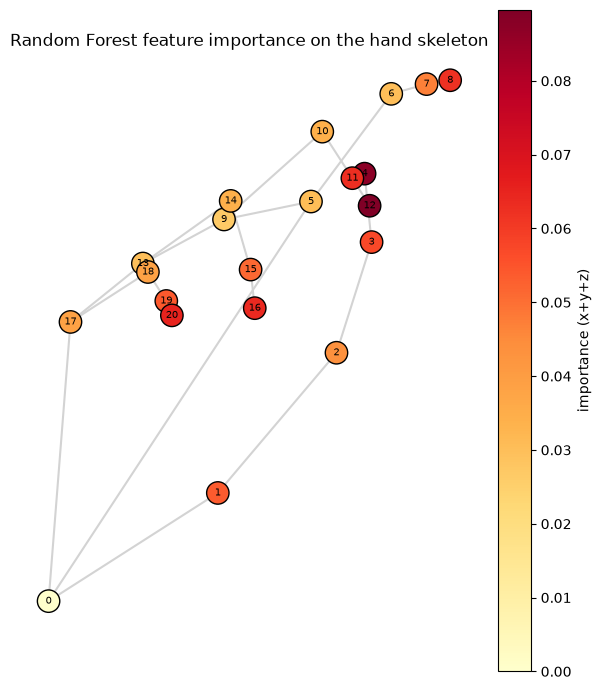

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
train = pd.read_csv(ROOT / "data/processed/train.csv")
feat_cols = [f"f{i}" for i in range(63)]
X = train[feat_cols].to_numpy(dtype=np.float64)
y = train["label"].astype(str).to_numpy()

rf = RandomForestClassifier(n_estimators=300, max_depth=20,
                            random_state=42, n_jobs=-1).fit(X, y)
imp63 = rf.feature_importances_
imp_lm = imp63.reshape(21, 3).sum(axis=1)        # har landmark: x + y + z ki importance
print("kul importance:", imp63.sum().round(3))

fingers = ["thumb", "index", "middle", "ring", "pinky"]
parts = ["mcp", "pip", "dip", "tip"]
lm_names = ["wrist"] + [f"{f}_{p}" for f in fingers for p in (["cmc", "mcp", "ip", "tip"] if f == "thumb" else parts)]
imp_df = pd.DataFrame({"landmark": range(21), "name": lm_names, "importance": imp_lm})
imp_df.to_csv(ROOT / "results/advanced_feature_importance.csv", index=False)
print(imp_df.sort_values("importance", ascending=False).head(8).round(4).to_string(index=False))

CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
               (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]
P = X.mean(axis=0).reshape(21, 3)                 # average haath ka shape

fig, ax = plt.subplots(figsize=(6, 7))
for a, b in CONNECTIONS:
    ax.plot([P[a, 0], P[b, 0]], [-P[a, 1], -P[b, 1]], color="lightgray", zorder=1)
sc = ax.scatter(P[:, 0], -P[:, 1], c=imp_lm, s=260, cmap="YlOrRd", edgecolors="k", zorder=2)
for i in range(21):
    ax.text(P[i, 0], -P[i, 1], str(i), ha="center", va="center", fontsize=7, zorder=3)
plt.colorbar(sc, label="importance (x+y+z)")
ax.set_title("Random Forest feature importance on the hand skeleton")
ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
fig.savefig(ROOT / "reports/figures/09_feature_importance_skeleton.png", dpi=150)
plt.show()